In [20]:
!pip install --upgrade pyspark==3.5.0 delta-spark==3.2.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.9/316.9 MB 33.5 MB/s  0:00:08
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached delta_spark-3.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached py4j-0.10.9.7-py2.py3-none-any.whl.metadata (1.5 kB)
Using cached delta_spark-3.2.0-py3-none-any.whl (21 kB)
Using cached py4j-0.10.9.7-py2.py3-none-any.whl (200 kB)
  Created wheel for pyspark: filename=pyspark-3.5.0-py2.py3-none-any.whl size=317425404 sha256=d4a713ec71963b25263f8372a9b97661b7c6cd0e699fb1e39cff0cd8d3f3d7b4
  Stored in directory: /root/.cache/pip/wheels/c5/8b/d4/f1198b4a868555ee18dcd7561b32418298d4c302010932c2ee
Successfully built pyspark
  Attempting uninstall: py4j
    Found existing installation: py4j 0.10.9.9
    Uninstalling py4j-0.10.9.9:
      Successfully uninstalled py4j-0.10.9.9
  Attempting uninstall: pyspark
    Found existing installation: pyspark 4.0.0
    Uninst

In [1]:
from delta import configure_spark_with_delta_pip
from pyspark.sql import SparkSession

builder = (
    SparkSession.builder.appName("CityWaterNetworkMonitoring")
    .master("local[*]")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config(
        "spark.sql.catalog.spark_catalog",
        "org.apache.spark.sql.delta.catalog.DeltaCatalog",
    )
)

spark = configure_spark_with_delta_pip(builder).getOrCreate()

In [ ]:
from google.colab import files

files.upload()

Saving water_meter_readings.csv to water_meter_readings.csv
Saving water_reading_changes.csv to water_reading_changes.csv
Saving water_readings_incremental.csv to water_readings_incremental.csv
Saving water_service_requests.csv to water_service_requests.csv
Saving water_zones.json to water_zones.json


{'water_meter_readings.csv': b'reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system\r\n1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway\r\n1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter\r\n1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp\r\n1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway\r\n1005,M005,W05,2026-10-01 11:10:00,61.8,3.04,0.43,2656,Suspect,SmartMeter\r\n1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp\r\n1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway\r\n1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter\r\n1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp\r\n1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway\r\n1011,M011,W01,2026-10-02 07:10:00,13.0,4.39,0.66,313,Valid,SmartMeter\r\n1012,M012,W02,2026-10-02 08:20:00,36.3,4.03,1.02

In [2]:
import os, glob
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DoubleType, TimestampType
from delta.tables import DeltaTable

def locate_file(expected):
    p = f"/content/{expected}"
    if os.path.exists(p):
        return p
    stem, ext = os.path.splitext(expected)
    matches = glob.glob(f"/content/{stem}*{ext}")
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Upload file not found: {expected}")

In [3]:
READING_SCHEMA = StructType([
    StructField("reading_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reading_time", TimestampType(), True),
    StructField("flow_lpm", DoubleType(), True),
    StructField("pressure_bar", DoubleType(), True),
    StructField("chlorine_mg_l", DoubleType(), True),
    StructField("consumption_liters", IntegerType(), True),
    StructField("reading_status", StringType(), True),
    StructField("source_system", StringType(), True)
])

In [4]:
def read_readings(filename):
    return (spark.read.format("csv").option("header", True)
        .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
        .schema(READING_SCHEMA).load(locate_file(filename)))

In [5]:
source = read_readings("water_meter_readings.csv")
changes = read_readings("water_reading_changes.csv")
incremental = read_readings("water_readings_incremental.csv")

In [6]:
zones_raw = spark.read.json(locate_file("water_zones.json"))
zones = zones_raw.select(
    "zone_id", "zone_name",
    F.col("location.city").alias("city"),
    F.col("location.district").alias("district"),
    "zone_type", "daily_capacity_liters", "active", "commissioned_on"
)

In [7]:
REQUEST_SCHEMA = StructType([
    StructField("request_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reported_at", TimestampType(), True),
    StructField("issue_type", StringType(), True),
    StructField("priority", StringType(), True),
    StructField("estimated_cost", DoubleType(), True),
    StructField("work_status", StringType(), True)
])

In [8]:
requests = (spark.read.format("csv").option("header", True)
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .schema(REQUEST_SCHEMA).load(locate_file("water_service_requests.csv")))

In [9]:
for name, df in [("meter readings", source), ("water zones JSON", zones),
                 ("service requests", requests), ("changes", changes),
                 ("incremental readings", incremental)]:
    print(name, "rows:", df.count())
    df.printSchema()

meter readings rows: 157
root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

water zones JSON rows: 11
root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)

service requests rows: 36
root
 |-- request_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- repor

In [10]:
display(zones)

DataFrame[zone_id: string, zone_name: string, city: string, district: string, zone_type: string, daily_capacity_liters: bigint, active: boolean, commissioned_on: string]

In [11]:
BASE = "/content/water_delta"
os.makedirs(BASE, exist_ok=True)

In [12]:
def save_delta(df, name, mode="overwrite"):
    path = f"{BASE}/{name}"
    df.write.format("delta").mode(mode).option("overwriteSchema", "true").save(path)
    return path

In [13]:
def read_delta(name):
    return spark.read.format("delta").load(f"{BASE}/{name}")

In [14]:
source_path = save_delta(source, "water_meter_readings_source")
work_path = save_delta(source, "water_meter_readings_work")
zones_path = save_delta(zones, "water_zones")
save_delta(zones_raw, "water_zones_raw")
save_delta(requests, "water_service_requests")
save_delta(changes, "water_reading_changes")
save_delta(incremental, "water_readings_incremental_staging")

'/content/water_delta/water_readings_incremental_staging'

In [15]:
source = read_delta("water_meter_readings_source")
work = read_delta("water_meter_readings_work")
zones = read_delta("water_zones")
requests = read_delta("water_service_requests")
changes = read_delta("water_reading_changes")
incremental = read_delta("water_readings_incremental_staging")

In [16]:
for df, view in [(source,"water_meter_readings_source"), (work,"water_meter_readings_work"),
                  (zones,"water_zones"), (requests,"water_service_requests"),
                  (changes,"water_reading_changes"), (incremental,"water_readings_incremental_staging")]:
    df.createOrReplaceTempView(view)

In [17]:
display(spark.sql("""SELECT reading_id, meter_id, zone_id, reading_time, consumption_liters
FROM water_meter_readings_source WHERE reading_status = 'Valid'"""))

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, consumption_liters: int]

In [18]:
display(spark.sql("""SELECT * FROM water_meter_readings_source
WHERE pressure_bar < 2.5 ORDER BY pressure_bar"""))

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

In [19]:
display(spark.sql("""SELECT * FROM water_meter_readings_source
WHERE flow_lpm BETWEEN 20 AND 50 AND source_system IN ('Gateway','SmartMeter')"""))

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

In [20]:
display(spark.sql("""SELECT reading_status, COUNT(*) AS reading_count
FROM water_meter_readings_source GROUP BY reading_status ORDER BY reading_count DESC"""))

DataFrame[reading_status: string, reading_count: bigint]

In [21]:
display(source.join(zones, "zone_id", "inner")
    .select("zone_name", "district", "meter_id", "consumption_liters"))

DataFrame[zone_name: string, district: string, meter_id: string, consumption_liters: int]

In [22]:
display(source.join(zones.select("zone_id"), "zone_id", "left_anti"))

DataFrame[zone_id: string, reading_id: int, meter_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

In [23]:
display(zones.join(source.select("zone_id").distinct(), "zone_id", "left_anti"))

DataFrame[zone_id: string, zone_name: string, city: string, district: string, zone_type: string, daily_capacity_liters: bigint, active: boolean, commissioned_on: string]

In [25]:
valid = source.filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))

zone_metrics = valid.groupBy("zone_id").agg(
    F.sum("consumption_liters").alias("total_valid_consumption"),
    F.avg("pressure_bar").alias("average_pressure"),
    F.count("*").alias("reading_count"))

display(zone_metrics.orderBy("zone_id"))

DataFrame[zone_id: string, total_valid_consumption: bigint, average_pressure: double, reading_count: bigint]

In [26]:
from pyspark.sql.window import Window

meter_district = (valid.join(zones.select("zone_id","district"), "zone_id")
    .groupBy("district","meter_id")
    .agg(F.sum("consumption_liters").alias("total_consumption")))

rank_window = Window.partitionBy("district").orderBy(F.desc("total_consumption"))

display(meter_district.withColumn("rank", F.dense_rank().over(rank_window)))

DataFrame[district: string, meter_id: string, total_consumption: bigint, rank: int]

In [27]:
display(source.groupBy("reading_id").count().filter(F.col("count") > 1))

DataFrame[reading_id: int, count: bigint]

In [28]:
display(source.filter(F.col("pressure_bar").isNull() | F.col("source_system").isNull()))

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

In [29]:
display(source.filter((F.col("flow_lpm") < 0) | (F.col("consumption_liters") <= 0) | F.col("zone_id").isNull()))

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

In [30]:
clean = (source.filter((F.col("reading_status") == "Valid") &
    (F.col("flow_lpm") > 0) & (F.col("pressure_bar") > 0) &
    (F.col("consumption_liters") > 0) & F.col("zone_id").isNotNull())
    .withColumn("rn", F.row_number().over(Window.partitionBy("reading_id").orderBy(F.desc("reading_time"))))
    .filter(F.col("rn") == 1).drop("rn"))

clean_path = save_delta(clean, "water_readings_clean")

display(clean)

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

In [31]:
high_zones = requests.filter(F.upper(F.col("priority")) == "HIGH").select("zone_id").distinct()

display(source.join(high_zones, "zone_id").groupBy("zone_id").agg(
    F.avg("pressure_bar").alias("avg_pressure"), F.count("*").alias("reading_count")))

DataFrame[zone_id: string, avg_pressure: double, reading_count: bigint]

In [32]:
copy_path = save_delta(work, "water_readings_work_copy")
copy_df = read_delta("water_readings_work_copy")

In [33]:
max_id = source.agg(F.max("reading_id")).first()[0] or 0
insert_rows = source.limit(2).withColumn("reading_id", F.col("reading_id") + F.lit(max_id + 10000))
insert_rows.write.format("delta").mode("append").save(copy_path)

In [34]:
copy_df = read_delta("water_readings_work_copy")

suspect = copy_df.filter(F.col("reading_status") == "Suspect").select("reading_id").first()

if suspect:
    DeltaTable.forPath(spark, copy_path).update(
        condition=f"reading_id = {suspect['reading_id']}",
        set={"reading_status": F.lit("Rejected")})

In [35]:
before = read_delta("water_readings_work_copy").count()
DeltaTable.forPath(spark, copy_path).delete("reading_status = 'Rejected'")
after = read_delta("water_readings_work_copy").count()
print("Before:", before, "After:", after, "Deleted:", before-after)

Before: 159 After: 149 Deleted: 10


In [36]:
DeltaTable.forPath(spark, work_path).alias("target").merge(
    changes.alias("source"), "target.reading_id = source.reading_id"
).whenMatchedUpdateAll().whenNotMatchedInsertAll().execute()

In [37]:
display(read_delta("water_meter_readings_work"))
display(DeltaTable.forPath(spark, work_path).history())
display(DeltaTable.forPath(spark, work_path).detail())

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

DataFrame[version: bigint, timestamp: timestamp, userId: string, userName: string, operation: string, operationParameters: map<string,string>, job: struct<jobId:string,jobName:string,jobRunId:string,runId:string,jobOwnerId:string,triggerType:string>, notebook: struct<notebookId:string>, clusterId: string, readVersion: bigint, isolationLevel: string, isBlindAppend: boolean, operationMetrics: map<string,string>, userMetadata: string, engineInfo: string]

DataFrame[format: string, id: string, name: string, description: string, location: string, createdAt: timestamp, lastModified: timestamp, partitionColumns: array<string>, clusteringColumns: array<string>, numFiles: bigint, sizeInBytes: bigint, properties: map<string,string>, minReaderVersion: int, minWriterVersion: int, tableFeatures: array<string>]

In [38]:
display(spark.read.format("delta").option("versionAsOf", 0).load(work_path))

DataFrame[reading_id: int, meter_id: string, zone_id: string, reading_time: timestamp, flow_lpm: double, pressure_bar: double, chlorine_mg_l: double, consumption_liters: int, reading_status: string, source_system: string]

In [40]:
bronze = source
silver = clean
gold = silver.join(zones.select("zone_id","zone_name","district"), "zone_id", "left").groupBy("zone_id","zone_name","district").agg(
        F.sum("consumption_liters").alias("total_consumption"),
        F.avg("pressure_bar").alias("average_pressure"),
        F.avg("chlorine_mg_l").alias("average_chlorine"),
        F.count("*").alias("reading_count"))

In [41]:
save_delta(bronze, "bronze_readings")
save_delta(silver, "silver_readings")
save_delta(gold, "gold_zone_summary")
display(gold.orderBy(F.desc("total_consumption")))

DataFrame[zone_id: string, zone_name: string, district: string, total_consumption: bigint, average_pressure: double, average_chlorine: double, reading_count: bigint]

In [42]:
incremental.write.format("delta").mode("append").save(source_path)
source = read_delta("water_meter_readings_source")

silver_updated = source.filter((F.col("reading_status") == "Valid") &
    (F.col("flow_lpm") > 0) & (F.col("consumption_liters") > 0))

gold_updated = silver_updated.join(zones.select("zone_id","zone_name","district"), "zone_id", "left")     .groupBy("zone_id","zone_name","district").agg(
        F.sum("consumption_liters").alias("total_consumption"),
        F.avg("pressure_bar").alias("average_pressure"),
        F.avg("chlorine_mg_l").alias("average_chlorine"),
        F.count("*").alias("reading_count"))

In [43]:
save_delta(gold_updated, "gold_zone_summary")
display(gold_updated)

DataFrame[zone_id: string, zone_name: string, district: string, total_consumption: bigint, average_pressure: double, average_chlorine: double, reading_count: bigint]

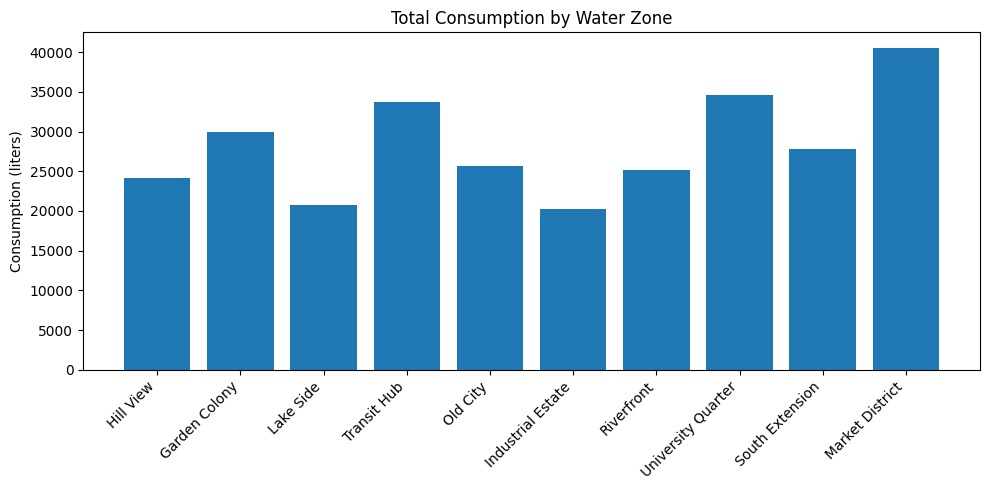

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

pdf = gold_updated.toPandas()

pdf["total_consumption"] = pd.to_numeric(
    pdf["total_consumption"], errors="coerce"
)
pdf["zone_name"] = pdf["zone_name"].astype(str).str.strip()

pdf = pdf.dropna(subset=["zone_name", "total_consumption"])
pdf = pdf[pdf["zone_name"] != ""]
pdf = pdf[pdf["zone_name"] != "None"]

plt.figure(figsize=(10, 5))
plt.bar(pdf["zone_name"], pdf["total_consumption"])
plt.xticks(rotation=45, ha="right")
plt.title("Total Consumption by Water Zone")
plt.ylabel("Consumption (liters)")
plt.tight_layout()
plt.show()

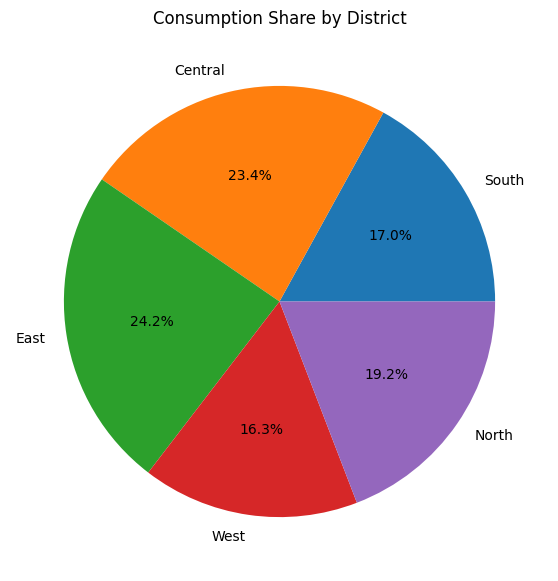

In [52]:
district_pdf = silver_updated.join(zones.select("zone_id","district"), "zone_id")     .groupBy("district").agg(F.sum("consumption_liters").alias("consumption")).toPandas()
plt.figure(figsize=(7,7))
plt.pie(district_pdf["consumption"], labels=district_pdf["district"], autopct="%1.1f%%")
plt.title("Consumption Share by District")
plt.show()

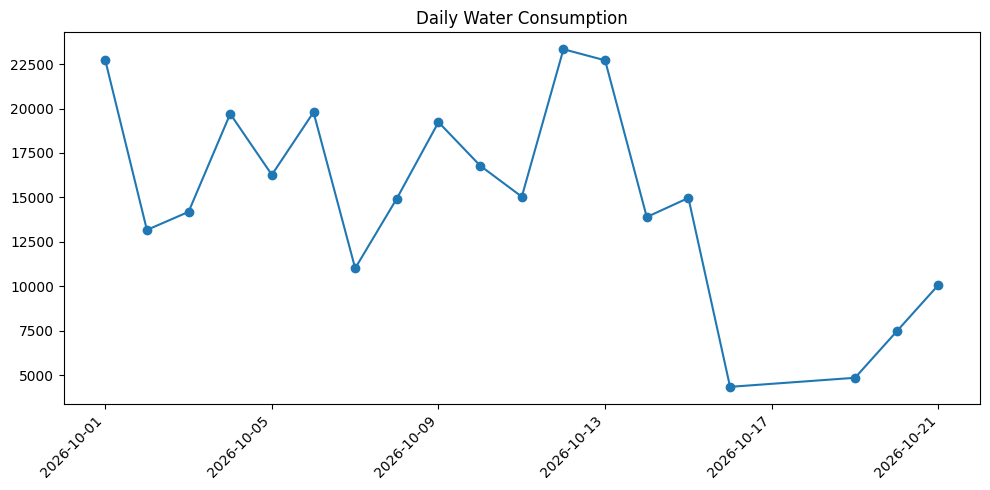

In [53]:
daily_pdf = silver_updated.withColumn("day", F.to_date("reading_time")).groupBy("day")     .agg(F.sum("consumption_liters").alias("consumption")).orderBy("day").toPandas()
plt.figure(figsize=(10,5))
plt.plot(daily_pdf["day"], daily_pdf["consumption"], marker="o")
plt.xticks(rotation=45, ha="right")
plt.title("Daily Water Consumption")
plt.tight_layout()
plt.show()

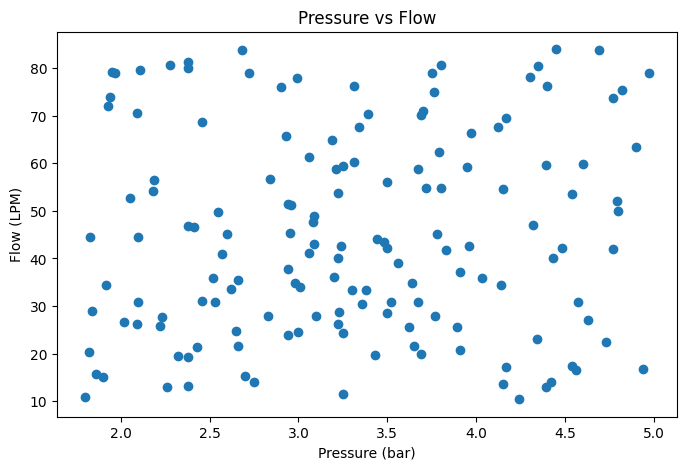

In [54]:
scatter_pdf = silver_updated.select("pressure_bar","flow_lpm").dropna().toPandas()
plt.figure(figsize=(8,5))
plt.scatter(scatter_pdf["pressure_bar"], scatter_pdf["flow_lpm"])
plt.xlabel("Pressure (bar)")
plt.ylabel("Flow (LPM)")
plt.title("Pressure vs Flow")
plt.show()

In [55]:
rate_stream = spark.readStream.format("rate").option("rowsPerSecond", 5).load()
water_stream = rate_stream.withColumn("meter_id", F.concat(F.lit("M"), F.col("value"))).withColumn("simulated_flow_lpm", (F.col("value") % 100).cast("double"))
high_flow_stream = water_stream.filter(F.col("simulated_flow_lpm") > 40)

In [56]:
stream_query = high_flow_stream.writeStream.format("console").outputMode("append").option("checkpointLocation", f"{BASE}/checkpoints/high_flow_demo").start()

In [57]:
stream_query.stop()